# RQ3: Scalability 

In [1]:
from pathlib import Path
import pandas as pd

service_folders = {
    3: Path("test_service_3"),
    5: Path("test_service_5"),
    8: Path("test_service_8"),
    10: Path("test_service_10"),
}

In [2]:
service_folders

{3: PosixPath('test_service_3'),
 5: PosixPath('test_service_5'),
 8: PosixPath('test_service_8'),
 10: PosixPath('test_service_10')}

In [3]:
all_results = []

for service_count, folder in service_folders.items():

    result_files = [
        file
        for file in folder.glob("*.csv")
        if file.name != "emissions.csv"
    ]

    print(f"{service_count} services: {len(result_files)} model CSV files")

    for file_path in result_files:

        df = pd.read_csv(file_path)

        df["service_count"] = service_count

        all_results.append(df)

scalability_df = pd.concat(
    all_results,
    ignore_index=True
)

3 services: 20 model CSV files
5 services: 20 model CSV files
8 services: 20 model CSV files
10 services: 20 model CSV files


In [4]:
scalability_df

,routing_method,query,raw_response,predicted_label,model_name,latency_ms,prompt_tokens,completion_tokens,total_tokens,query_id,expected_service,is_correct,error,specialist_service_count,total_service_count,service_count
0,bi-encoder,Statement 1 | If a group has an element of ord...,NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,340.013249,65,0,65,0,abstract_algebra,True,NaN,3,4,3
1,bi-encoder,"Statement 1 | If G, H and K are groups of orde...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,92.170244,58,0,58,1,abstract_algebra,True,NaN,3,4,3
2,bi-encoder,"(Z,*) is a group with a*b = a+b+1 for all a, b...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,121.192111,28,0,28,2,abstract_algebra,True,NaN,3,4,3
3,bi-encoder,"Statement 1 | For any two groups G and G', the...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,99.521041,39,0,39,3,abstract_algebra,True,NaN,3,4,3
4,bi-encoder,"Let A and B be sets, f: A -> B and g: B -> A b...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,87.685089,63,0,63,4,abstract_algebra,True,NaN,3,4,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,llm,Allen's (2001) study of nurses showed that:,jurisprudence,jurisprudence,llama3.1:8b,304.938247,867,5,872,1095,general,False,NaN,10,11,10
59996,llm,The term 'secondary deviation' refers to:,formal_logic,formal_logic,llama3.1:8b,300.741887,864,4,868,1096,general,False,NaN,10,11,10
59997,llm,Murray thought that the 'underclass' consisted...,service general,general,llama3.1:8b,424.749427,869,3,872,1097,general,True,NaN,10,11,10
59998,llm,"According to Foucault, carceral organizations:",jurisprudence,jurisprudence,llama3.1:8b,466.334821,865,5,870,1098,general,False,NaN,10,11,10


In [5]:
print(scalability_df.shape)

scalability_df.groupby("service_count").size()

(60000, 16)


service_count
3      8000
5     12000
8     18000
10    22000
dtype: int64

In [6]:
scalability_summary = (
    scalability_df
    .groupby(
        ["routing_method", "model_name", "service_count"]
    )
    .agg(
        accuracy=("is_correct", "mean"),
        n_queries=("is_correct", "size")
    )
    .reset_index()
)

scalability_summary["accuracy_percent"] = (
    scalability_summary["accuracy"] * 100
)

scalability_summary[
    [
        "routing_method",
        "model_name",
        "service_count",
        "accuracy_percent",
        "n_queries"
    ]
].round(2)

,routing_method,model_name,service_count,accuracy_percent,n_queries
0,bi-encoder,BAAI/bge-large-en-v1.5,3,84.00,400
1,bi-encoder,BAAI/bge-large-en-v1.5,5,82.17,600
2,bi-encoder,BAAI/bge-large-en-v1.5,8,79.44,900
3,bi-encoder,BAAI/bge-large-en-v1.5,10,79.73,1100
4,bi-encoder,Qwen/Qwen3-Embedding-0.6B,3,93.50,400
...,...,...,...,...,...
75,llm,qwen2.5:7b,10,64.64,1100
76,llm,qwen3:32b,3,96.25,400
77,llm,qwen3:32b,5,94.33,600
78,llm,qwen3:32b,8,90.67,900


In [7]:
scalability_table = (
    scalability_summary
    .pivot(
        index=["routing_method", "model_name"],
        columns="service_count",
        values="accuracy_percent"
    )
    .reset_index()
)

scalability_table.columns.name = None

scalability_table = scalability_table.rename(
    columns={
        3: "3_services",
        5: "5_services",
        8: "8_services",
        10: "10_services"
    }
)

scalability_table["change_3_to_10"] = (
    scalability_table["10_services"]
    - scalability_table["3_services"]
)

scalability_table.round(2)

,routing_method,model_name,3_services,5_services,8_services,10_services,change_3_to_10
0,bi-encoder,BAAI/bge-large-en-v1.5,84.00,82.17,79.44,79.73,-4.27
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,93.50,84.33,74.00,73.45,-20.05
2,bi-encoder,Qwen/Qwen3-Embedding-4B,94.00,84.00,74.11,74.82,-19.18
3,bi-encoder,Qwen/Qwen3-Embedding-8B,93.00,84.00,78.11,77.55,-15.45
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,86.25,77.33,73.78,73.00,-13.25
5,colbert,LiquidAI/LFM2-ColBERT-350M,91.00,83.83,79.56,73.18,-17.82
6,colbert,colbert-ir/colbertv2.0,81.25,70.50,65.67,62.91,-18.34
7,colbert,lightonai/Reason-ModernColBERT,90.75,82.17,78.22,75.91,-14.84
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,89.00,79.67,72.89,72.00,-17.00
9,cross-encoder,BAAI/bge-reranker-v2-m3,80.50,74.83,68.89,68.18,-12.32


In [11]:
architecture_summary = (
    scalability_summary
    .groupby(
        ["routing_method", "service_count"]
    )["accuracy_percent"]
    .mean()
    .reset_index(name="mean_accuracy")
)

architecture_summary["mean_accuracy"] = (
    architecture_summary["mean_accuracy"].round(2)
)

architecture_summary

,routing_method,service_count,mean_accuracy
0,bi-encoder,3,90.15
1,bi-encoder,5,82.37
2,bi-encoder,8,75.89
3,bi-encoder,10,75.71
4,colbert,3,88.00
5,colbert,5,79.04
6,colbert,8,74.08
7,colbert,10,71.00
8,cross-encoder,3,89.75
9,cross-encoder,5,86.60


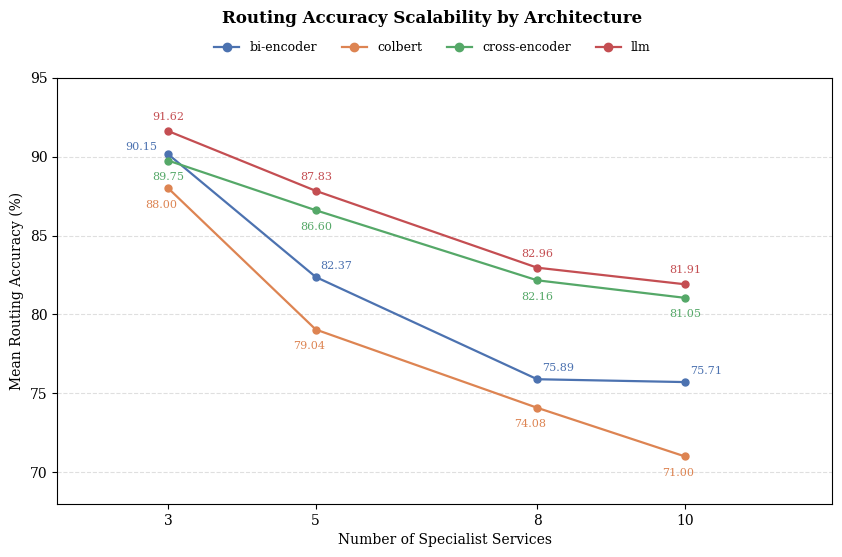

In [87]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

approach_order = ["bi-encoder", "colbert", "cross-encoder", "llm"]
architecture_summary["routing_method"] = pd.Categorical(
    architecture_summary["routing_method"], categories=approach_order, ordered=True
)
architecture_summary = architecture_summary.sort_values(
    ["routing_method", "service_count"]
).reset_index(drop=True)

mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.edgecolor": "black",
    "axes.linewidth": 0.8,
})

colors = {
    "bi-encoder": "#4C72B0",
    "colbert": "#DD8452",
    "cross-encoder": "#55A868",
    "llm": "#C44E52",
}

fig, ax = plt.subplots(figsize=(10, 6)) 

for method in approach_order:
    sub = architecture_summary[architecture_summary["routing_method"] == method]
    ax.plot(sub["service_count"], sub["mean_accuracy"],
            marker="o", markersize=5, linewidth=1.6,
            color=colors[method], label=method, zorder=3)

# label LLM
llm_sub = architecture_summary[architecture_summary["routing_method"] == "llm"]
for x, y in zip(llm_sub["service_count"], llm_sub["mean_accuracy"]):
    ax.annotate(f"{y:.2f}", (x, y),
                textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8, color=colors["llm"])
    
# label cross-encoder
cross_sub = architecture_summary[architecture_summary["routing_method"] == "cross-encoder"]
for x, y in zip(cross_sub["service_count"], cross_sub["mean_accuracy"]):
    ax.annotate(f"{y:.2f}", (x, y),
                textcoords="offset points", xytext=(0, -14),
                ha="center", fontsize=8, color=colors["cross-encoder"])

# label bi-encoder
bi_sub = architecture_summary[architecture_summary["routing_method"] == "bi-encoder"]
for x, y in zip(bi_sub["service_count"], bi_sub["mean_accuracy"]):
    if x == 3:
        offset = (-8, 3)
        ha = "right"
    else:
        offset = (15, 6)
        ha = "center"
    ax.annotate(f"{y:.2f}", (x, y),
                textcoords="offset points", xytext=offset,
                ha=ha, fontsize=8, color=colors["bi-encoder"])
    
colbert_sub = architecture_summary[architecture_summary["routing_method"] == "colbert"]
for x, y in zip(colbert_sub["service_count"], colbert_sub["mean_accuracy"]):
    ax.annotate(f"{y:.2f}", (x, y),
                textcoords="offset points", xytext=(-5, -14),
                ha="center", fontsize=8, color=colors["colbert"])
    
ax.set_xticks([3, 5, 8, 10])
ax.set_xlim(1.5, 12)
ax.set_xlabel("Number of Specialist Services")
ax.set_ylabel("Mean Routing Accuracy (%)")
ax.set_ylim(68, 95)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

fig.suptitle("Routing Accuracy Scalability by Architecture",
             fontsize=12, weight="bold", y=0.933)

handles = [plt.Line2D([0], [0], color=colors[k], marker="o", linewidth=1.6) for k in approach_order]
fig.legend(handles, approach_order, loc="upper center", bbox_to_anchor=(0.5, 0.90),
           ncol=4, frameon=False, fontsize=9)

plt.subplots_adjust(top=0.82)

plt.savefig("rq3_scalability_lineplot.pdf", bbox_inches="tight")
plt.show()

In [14]:
# table_for_latex = scalability_table.rename(
#     columns={
#         "routing_method": "Architecture",
#         "model_name": "Model",
#         "3_services": "3 services (\\%)",
#         "5_services": "5 services (\\%)",
#         "8_services": "8 services (\\%)",
#         "10_services": "10 services (\\%)",
#         "change_3_to_10": "$\\Delta$ 3--10 (pp)"
#     }
# )

# latex_table = table_for_latex.round(2).to_latex(
#     index=False,
#     escape=False,
#     column_format="llrrrrr"
# )

# print(latex_table)